# Pre-entrega 3 · Clasificación supervisada de noticias con TF-IDF
**Hans Dresda | Data Science III | AG News**

**Objetivo:** El objetivo de esta entrega es consolidar la pieza incremental de tu proyecto final. Deberás entregar un artefacto que demuestre la capacidad de llevar el texto crudo a una predicción de categoría utilizando técnicas aprendidas en este módulo.

In [1]:
from pathlib import Path
import html
import re
import unicodedata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spacy
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, confusion_matrix, f1_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

SEED = 42
folders = [Path("data"), Path("."), Path("data/ag_news"), Path("../data/ag_news")]
data_dir = next((p for p in folders if all((p / f"ag_news_{s}.csv").is_file()
                                          for s in ("train", "test"))), None)
if data_dir is None:
    raise FileNotFoundError("Coloca ag_news_train.csv y ag_news_test.csv en la carpeta data/.")

def load_split(name):
    frame = pd.read_csv(data_dir / f"ag_news_{name}.csv")
    assert {"text", "label"}.issubset(frame.columns)
    assert frame[["text", "label"]].notna().all().all()
    assert frame.text.str.strip().ne("").all()
    return frame

train = load_split("train")
labels = sorted(train.label.unique())
assert set(labels) == {"Sports", "Sci_Tech", "World", "Business"}
display(train.label.value_counts().sort_index().rename("Noticias de entrenamiento").to_frame())

,Noticias de entrenamiento
label,
Business,2000
Sci_Tech,2000
Sports,2000
World,2000


## 1. Recuperar la preparación del módulo 2
Reutilizamos las funciones de la pre-entrega 2 (`clean_text()`, `word_tokens()` y `preprocess_text())` para reparar entidades HTML, retirar firmas de agencia, normalizar variantes de US y obtener lemas en inglés. Conservamos *no*, *not* y *never*. La limpieza opera sobre cada noticia de forma independiente y el modelo de spaCy ya está entrenado. Por eso se puede procesar el texto por lotes antes de la validación cruzada. El vocabulario y el IDF sí dependen del corpus y se ajustarán dentro de cada pliegue.

In [2]:
nlp = spacy.load('en_core_web_sm', disable=['ner', 'parser'])
keep = {'no', 'not', 'never'}
stops = nlp.Defaults.stop_words

def clean_text(text):
    text = unicodedata.normalize('NFKC', text)
    text = re.sub(r'(?<!&)#(\d{2,5});', r'&#\1;', text)
    text = html.unescape(html.unescape(text))
    text = re.sub(r'</?[A-Za-z][^<>]*>', ' ', text)
    # Firmas de agencia en encabezados y enlaces bursátiles de la fuente.
    text = re.sub(r'\((AP|AFP|Reuters|Canadian Press)\)\.?\s*\1\s*[-–—]', ' ', text, flags=re.I)
    text = re.sub(r'\((?:AP|AFP|Reuters|CP|Canadian Press)\)\s*[-–—]?', ' ', text, flags=re.I)
    text = re.sub(r'\([^()]{0,35}:\s*Quote,\s*Profile,\s*Research\)', ' ', text, flags=re.I)
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text, flags=re.I)
    text = re.sub(r'\b(?:U\.S\.(?:A\.)?|US|USA)(?!\w)', 'USA', text)
    text = re.sub(r"\s+['’]s\b", "'s", text)
    return ' '.join(text.split())

def word_tokens(doc, filter_stops=True):
    words = []
    for token in doc:
        lemma = token.lemma_.casefold()
        if not lemma.isalpha() or len(lemma) < 2:
            continue
        if filter_stops and lemma not in keep and (token.is_stop or lemma in stops):
            continue
        words.append(lemma)
    return words

def preprocess_text(text):
    return ' '.join(word_tokens(nlp(clean_text(text))))


def preprocess_batch(series):
    documents = nlp.pipe((clean_text(t) for t in series), batch_size=128)
    return pd.Series((" ".join(word_tokens(doc)) for doc in documents), index=series.index)

x_train = preprocess_batch(train.text)
assert x_train.ne("").all()
assert x_train.iloc[0] == preprocess_text(train.text.iloc[0])
print("Original:", train.text.iloc[0])
print("Texto para TF-IDF:", x_train.iloc[0])

Original: Red Hat Appoints New CFO. September 2, 2004 -- (WEB HOST INDUSTRY REVIEW) -- Linux distributor Red Hat (redhat.com) announced on Thursday that it has appointed Charles E. Peters, Jr.
Texto para TF-IDF: red hat appoints new cfo september web host industry review linux distributor red hat announce thursday appoint charles peters


## 2. Comparar representaciones con validación cruzada
Para el modelado elegimos **SVM lineal** porque aprende fronteras entre categorías directamente sobre una matriz dispersa y permite inspeccionar los pesos de sus términos. No necesitamos probabilidades para elegir una de cuatro etiquetas. Mantener el clasificador fijo permite atribuir las diferencias observadas a la vectorización.

Cruzamos dos límites de vocabulario (10 000 y 50 000) con dos rangos de n-gramas. Los bigramas pueden capturar expresiones como *oil price*, aunque incorporarlos consume espacio que también podrían ocupar unigramas. Con `min_df=2` exigimos dos documentos del pliegue de ajuste. Aplicamos IDF suavizado y normalización L2. El límite de vocabulario es un máximo, por lo que el número de términos efectivos puede ser menor.

Usamos los mismos tres pliegues estratificados y la misma semilla en todos los experimentos. En cada ajuste, el Pipeline ejecuta `fit_transform` sobre el subentrenamiento y `transform` sobre la validación. El modelo trivial predice siempre la categoría mayoritaria del pliegue y sirve de referencia.

In [ ]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
dummy = DummyClassifier(strategy="most_frequent")
dummy_cv = cross_val_score(dummy, x_train, train.label, cv=cv, scoring="f1_macro")
print(f"Referencia trivial · F1 macro medio: {dummy_cv.mean():.4f}")

##Vectorización: Implementar TfidfVectorizer

# Parámetros de TfidfVectorizer:
# tokenizer=str.split: separa el texto por espacios. Es coherente con x_train, que ya contiene los tokens preprocesados separados por espacios.
# token_pattern=None: desactiva el patrón de tokens predeterminado, que no hace falta al proporcionar un tokenizer propio.
# lowercase=False: evita que el vectorizador vuelva a convertir a minúsculas el texto que ya llega normalizado.
# min_df=2: descarta términos que aparecen en menos de dos documentos, reduciendo el efecto de palabras muy raras.
# smooth_idf=True: suaviza el cálculo del peso IDF para evitar valores extremos.
# norm="l2": normaliza cada vector de noticia; ayuda a que el peso total de un documento no dependa simplemente de su longitud.
# max_features (limitar el vocabulario para evitar overfitting).
# ngram_range (incluir unigramas y bigramas).

##Modelo: Implementar LinearSVC

# Parámetros de LinearSVC:
# C=1.0: fija la regularización, es decir, el equilibrio entre ajustar los datos de entrenamiento y limitar la complejidad del clasificador.
# random_state=SEED: fija la semilla para que los aspectos aleatorios del ajuste sean reproducibles cuando corresponda.
# max_iter=5000: establece el máximo de iteraciones para que el algoritmo converja.


pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(min_df=2, tokenizer=str.split, token_pattern=None,
                              lowercase=False, smooth_idf=True, norm="l2")),
    ("svm", LinearSVC(C=1.0, random_state=SEED, max_iter=5000)),
])
grid = {"tfidf__max_features": [10_000, 50_000],
        "tfidf__ngram_range": [(1, 1), (1, 2)]}
search = GridSearchCV(pipeline, grid, scoring="f1_macro", cv=cv,
                      refit=True, n_jobs=1, error_score="raise")
search.fit(x_train, train.label)
scores = pd.DataFrame(search.cv_results_)[
    ["param_tfidf__max_features", "param_tfidf__ngram_range",
     "mean_test_score", "std_test_score", "rank_test_score"]
].copy()
scores.columns = ["Máximo de términos", "N-gramas", "F1 macro CV", "Desv. entre pliegues", "Puesto"]
display(scores.sort_values("Puesto").round(4))
model = search.best_estimator_
vectorizer = model.named_steps["tfidf"]
print("Selección por F1 macro:", search.best_params_)
print("Vocabulario efectivo tras reajustar con todo train:", len(vectorizer.vocabulary_))

Referencia trivial · F1 macro medio: 0.0999


,Máximo de términos,N-gramas,F1 macro CV,Desv. entre pliegues,Puesto
3,50000,"(1, 2)",0.8793,0.0075,1
1,10000,"(1, 2)",0.8748,0.0084,2
0,10000,"(1, 1)",0.8721,0.0087,3
2,50000,"(1, 1)",0.8721,0.0087,3


Selección por F1 macro: {'tfidf__max_features': 50000, 'tfidf__ngram_range': (1, 2)}
Vocabulario efectivo tras reajustar con todo train: 24929


## 3. Evaluar una sola configuración en la prueba oficial
Con la configuración ya seleccionada, `refit=True` ha reajustado el pipeline en todo el entrenamiento. Ahora procesamos la prueba con las mismas reglas y llamamos a `predict`. El vectorizador reutiliza los pesos y columnas aprendidos. El reporte distingue precisión (aciertos entre las predicciones de una clase), recall (aciertos entre sus noticias reales), F1 y soporte (cantidad real de noticias).

              precision    recall  f1-score   support

    Business     0.8362    0.8680    0.8518       500
    Sci_Tech     0.8841    0.8700    0.8770       500
      Sports     0.9453    0.9680    0.9565       500
       World     0.9203    0.8780    0.8987       500

    accuracy                         0.8960      2000
   macro avg     0.8965    0.8960    0.8960      2000
weighted avg     0.8965    0.8960    0.8960      2000

Aciertos: 1792 de 2000 | Errores: 208


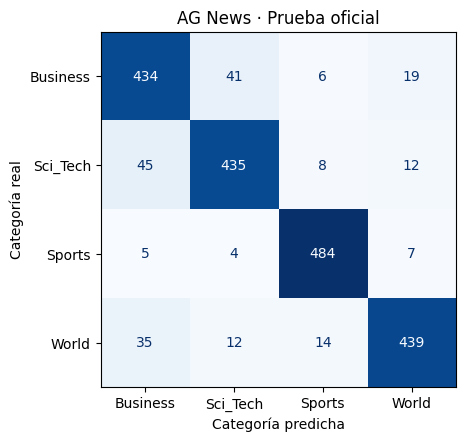

In [4]:
test = load_split("test")
assert set(test.label) == set(labels)
assert set(train.text).isdisjoint(test.text), "Hay textos idénticos entre particiones."
x_test = preprocess_batch(test.text)
pred = model.predict(x_test)
report = classification_report(test.label, pred, labels=labels, output_dict=True, zero_division=0)
print(classification_report(test.label, pred, labels=labels, digits=4, zero_division=0))
cm = confusion_matrix(test.label, pred, labels=labels)
hits = int(cm.trace())
print(f"Aciertos: {hits} de {len(test)} | Errores: {len(test) - hits}")

fig, ax = plt.subplots(figsize=(6.4, 4.3), layout="constrained")
ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set(xlabel="Categoría predicha", ylabel="Categoría real", title="AG News · Prueba oficial")
plt.show()

## 4. Diagnosticar errores y revisar titulares
La diagonal cuenta aciertos. Cada celda fuera de ella indica la dirección del error. Para distinguir problemas de cobertura de problemas de precisión, relacionamos la matriz con el reporte y recuperamos tres noticias de la confusión más frecuente.

In [ ]:
## Definimos que métricas mostrar y cómo mostrar los errores más frecuentes.
metrics = pd.DataFrame(report).T.loc[labels, ["precision", "recall", "f1-score", "support"]]
display(metrics.sort_values("f1-score").round(4))
errors = cm.copy()
np.fill_diagonal(errors, 0)
row, col = np.unravel_index(errors.argmax(), errors.shape)
actual, mistaken = labels[row], labels[col]
print(f"{actual} → {mistaken}: {errors[row, col]} de {cm[row].sum()} noticias reales de {actual}.")
cases = test.loc[test.label.eq(actual) & (pred == mistaken), "text"].head(3)
for index, article in cases.items():
    print(f"Fila {index}: {article}")

,precision,recall,f1-score,support
Business,0.8362,0.868,0.8518,500.0
Sci_Tech,0.8841,0.870,0.8770,500.0
World,0.9203,0.878,0.8987,500.0
Sports,0.9453,0.968,0.9565,500.0


Sci_Tech → Business: 45 de 500 noticias reales de Sci_Tech.
Fila 45: E.U. Regulators Approve Oracle's PeopleSoft Bid. European Union antitrust regulators on Tuesday cleared Oracle Corp.'s hostile $7.7 billion bid for rival business software maker PeopleSoft Inc., removing one of the last major hurdles to the contested takeover proposal.
Fila 47: Make hotels just like home. HOTEL operators, take note: Todays hotel guests are making a nonsense of room-pricing strategies with their aggressive, Internet-aided discount-hunting.
Fila 108: Supreme Court Asked To Hear File-Sharing Arguments. The file-sharing legal battle has moved to the Supreme Court, with a group composed of labor unions, sports leagues and state attorneys general asking for a hearing on a claim brought


## 5. Del texto crudo a la predicción
Para clasificar una noticia inédita se aplican la función de limpieza del módulo 2 y el pipeline ajustado. La siguiente oración es un ejemplo ilustrativo independiente de las métricas.

In [6]:
headline = "The tennis champion won the final in straight sets."
print("Noticia:", headline)
print("Categoría predicha:", model.predict([preprocess_text(headline)])[0])

Noticia: The tennis champion won the final in straight sets.
Categoría predicha: Sports


## Conclusiones de la ejecución

La mejor combinación fue unigramas y bigramas con un límite de 50 000 términos. Su F1 macro medio en validación fue 0,8793, frente a 0,8721 con unigramas. Con bigramas y un máximo de 10 000 términos se obtuvo 0,8750. La mejora observada es pequeña y se interpreta sobre los tres pliegues utilizados. Después del ajuste final quedaron 24 929 términos efectivos.

En la prueba oficial, el modelo acertó 1 792 de 2 000 noticias (89,60 %) y logró un F1 macro de 0,8960. Sports fue la categoría más fácil (F1 de 0,9565, con 484 aciertos de 500). Business tuvo el menor F1 (0,8518) y la menor precisión (0,8362). Las clases tienen el mismo soporte, por lo que el F1 ponderado y el macro coinciden en esta prueba.

El principal cruce fue Sci_Tech → Business (45 casos), seguido de Business → Sci_Tech (41). En conjunto explican 86 de los 208 errores (41,3 %). La adquisición de PeopleSoft por Oracle ilustra el solapamiento: una misma noticia trata de software, empresas y una oferta de compra. La matriz señala dónde investigar; los ejemplos sugieren ambigüedad temática y se necesitaría revisar una muestra mayor para cuantificarla. Estos resultados constituyen la referencia para comparar el futuro Transformer sobre la misma prueba.
